# Лабораторная работа №2
## Классификация твитов о стихийных бедствиях

**Выполнил:** Акимов Александр, гр. 4374

---

**Цель работы:** построить модель машинного обучения, которая определяет, сообщает ли твит о реальном стихийном бедствии.

**Задача:** бинарная классификация — предсказать значение `target` для каждого твита.

**Источник данных:** [Kaggle — Natural Language Processing with Disaster Tweets](https://www.kaggle.com/competitions/nlp-getting-started)

**Метрика оценки:** F1-score.

## 1. Загрузка данных и первичный осмотр

1. Загрузим размеченные данные из `data/train.csv`.
2. Посмотрим на первые пять строк и проверим, как прочитались поля.
3. Выведем размер таблицы, типы столбцов и количество непустых значений.

In [130]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/train.csv')
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7613 non-null   int64
 1   keyword   7552 non-null   str  
 2   location  5080 non-null   str  
 3   text      7613 non-null   str  
 4   target    7613 non-null   int64
dtypes: int64(2), str(3)
memory usage: 1.2 MB


## 2. Разведочный анализ данных (EDA)

### 2.1. Пропуски

1. Посчитаем пропуски по каждому столбцу.
2. Проверим, заполнены ли текст твита `text` и целевая переменная `target`.

In [132]:
df.isna().sum().rename("Пропуски")

id             0
keyword       61
location    2533
text           0
target         0
Name: Пропуски, dtype: int64

**Вывод.** В `text` и `target` пропусков нет, поэтому на этом этапе удалять
строки из-за пропусков не требуется. В `keyword` пропущено 61 значение,
а в `location` — 2533 (около трети строк). В качестве входных данных для
первой модели используем `text`. Пользу дополнительных полей можно проверить
отдельным экспериментом.

### 2.2. Распределение целевой переменной

1. Посчитаем твиты каждого класса. Метка `0` означает, что твит не связан с реальным
   бедствием, а `1` — что связан.
2. Вычислим долю каждого класса в процентах и выведем её рядом с количеством.

In [133]:
target_counts = df['target'].value_counts().sort_index()
target_shares = (target_counts / target_counts.sum() * 100).round(2)

pd.DataFrame({
    'Количество': target_counts,
    'Доля, %': target_shares,
})

,Количество,"Доля, %"
target,,
0,4342,57.03
1,3271,42.97


**Вывод.** Класс `0` составляет 57,03% выборки, класс `1` — 42,97%.
При разбиении используем стратификацию по `target`, чтобы сохранить примерно
такое же соотношение классов в обеих частях.

### 2.3. Повторяющиеся тексты

1. Найдём строки с одинаковым `text` и выведем несколько примеров.
2. Посчитаем, у скольких уникальных текстов встречаются обе метки `target`.
3. Посчитаем, сколько строк содержат такие тексты.

In [134]:
duplicate_mask = df['text'].duplicated(keep=False)
duplicates = df.loc[duplicate_mask, ['id', 'text', 'target']]
duplicates.sort_values('text').head()

,id,text,target
4290,6094,#Allah describes piling up #wealth thinking it...,0
4299,6105,#Allah describes piling up #wealth thinking it...,0
4312,6123,#Allah describes piling up #wealth thinking it...,1
6363,9095,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6366,9098,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1


In [135]:
label_counts = duplicates.groupby('text')['target'].nunique()
conflicts = label_counts[label_counts > 1]
conflict_mask = df['text'].isin(conflicts.index)

print(f'Уникальных текстов с противоречивыми метками: {len(conflicts)}')
print(f'Строк с такими текстами: {conflict_mask.sum()}')

Уникальных текстов с противоречивыми метками: 18
Строк с такими текстами: 55


**Вывод.** В `train.csv` обнаружено 18 уникальных текстов с противоречивыми
метками `target`. Они встречаются в 55 строках, что составляет
около 0,72% обучающего набора. По имеющимся данным нельзя установить,
какая метка верна для каждого такого текста.

При разбиении строки с одинаковым текстом поместим в одну часть,
чтобы модель не оценивалась на текстах, которые уже видела при обучении.
После построения базовой модели проверим, влияет ли исключение
конфликтных строк из обучающей части на F1. Для обоих вариантов
используем одну и ту же проверочную выборку.

### 2.4. Длина твитов

1. Измерим длину каждого твита в символах и проверим расчёт на первых строках.
2. Сравним медианы и квартильные значения длины для классов `0` и `1`.
3. Построим гистограмму с долями внутри каждого класса, чтобы увидеть,
   насколько распределения перекрываются.

In [136]:
df['text_length'] = df['text'].str.len()
df[['text', 'text_length', 'target']].head()

,text,text_length,target
0,Our Deeds are the Reason of this #earthquake M...,69,1
1,Forest fire near La Ronge Sask. Canada,38,1
2,All residents asked to 'shelter in place' are ...,133,1
3,"13,000 people receive #wildfires evacuation or...",65,1
4,Just got sent this photo from Ruby #Alaska as ...,88,1


In [137]:
df.groupby('target')['text_length'].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,4342.0,95.706817,35.885924,7.0,68.0,101.0,130.0,157.0
1,3271.0,108.113421,29.309854,14.0,88.0,115.0,136.0,151.0


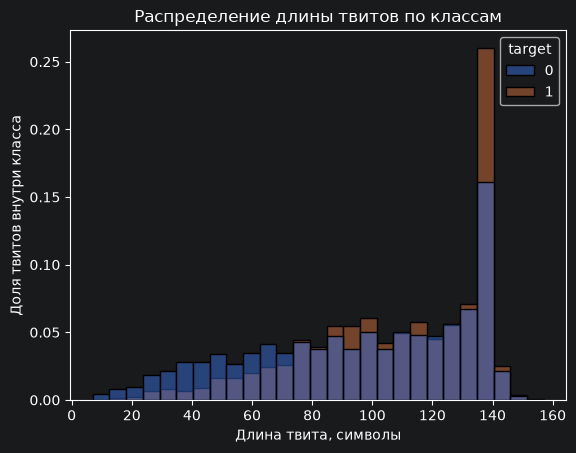

In [138]:
ax = sns.histplot(
    data=df,
    x='text_length',
    hue='target',
    stat='probability',
    common_norm=False,
)
ax.set(
    title='Распределение длины твитов по классам',
    xlabel='Длина твита, символы',
    ylabel='Доля твитов внутри класса',
)
plt.show()

**Вывод.** Медиана длины составляет 101 символ у класса `0` и 115 символов
у класса `1`. У класса `1` заметнее пик около 135–140 символов, но распределения
сильно перекрываются. Вклад длины как дополнительного признака можно
проверить по изменению F1.

### 2.5. Ссылки и хэштеги

1. Отметим твиты со ссылками `http://` и `https://` и сравним их доли по классам.
2. Отметим твиты с хэштегами и сравним их доли по классам.

In [139]:
df['has_url'] = df['text'].str.contains('https?://')
url_share = df.groupby('target')['has_url'].mean() * 100
url_share.round(2).to_frame('Твиты со ссылкой, %')

,"Твиты со ссылкой, %"
target,
0,41.43
1,66.40


In [140]:
df['has_hashtag'] = df['text'].str.contains(r'#\w+')
hashtag_share = df.groupby('target')['has_hashtag'].mean() * 100
hashtag_share.round(2).to_frame('Твиты с хэштегом, %')

,"Твиты с хэштегом, %"
target,
0,20.38
1,26.23


**Вывод.** Ссылки встречаются в 41,4% твитов класса `0` и 66,4% твитов
класса `1`. Разница составляет около 25 процентных пунктов. Для хэштегов
доли составляют 20,4% и 26,2% соответственно, с разницей около 5,8
процентного пункта. Вклад этих признаков проверим по изменению F1.

### 2.6. Примеры твитов

1. Выберем по три случайных твита из каждого класса.
2. Выведем тексты рядом с метками и посмотрим, как контекст помогает понять класс.

In [141]:
df[['target', 'text']].groupby('target').sample(n=3, random_state=42)

,target,text
3697,0,Everyday is a near death fatality for me on th...
4180,0,#Lifestyle Û÷It makes me sickÛª: Baby clothe...
4634,0,@Lenn_Len Probably. We are inundated with them...
3162,1,Came across this fire video not mine..enjoy..#...
4558,1,#BreakingNews Militants attack Udhampur police...
3320,1,Tonight is being quite interesting... A few mi...


**Вывод.** В примере класса `0` выражение «near death fatality» описывает
повседневные поездки автора. В примере класса `1` фраза «we had to evacuate
the building» описывает конкретную эвакуацию. Оба текста содержат тревожные
слова, и смысл становится понятнее по остальной фразе.

## 3. Разбиение данных

1. Выделим текст твита как вход модели, а `target` — как целевую переменную.
2. Получим обучающую и проверочную части `train.csv` в примерном соотношении
   80:20. Для этого возьмём первое разбиение `StratifiedGroupKFold` с пятью
   частями. Группировка по `text` удержит одинаковые тексты в одной части,
   а стратификация поможет сохранить доли классов.
3. Проверим размеры выборок, доли классов и отсутствие одинаковых текстов
   в обеих частях.

На обучающей части будем обучать модели, на проверочной — сравнивать их
по F1. Файл `test.csv` предназначен для предсказаний и отправки на Kaggle.